Creating greenwashing label in dataset

In [ ]:
pip install pandas torch transformers scikit-learn

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("/content/preprocessed_content.csv")

# Create greenwashing label
median_score = df['total_score'].median()

df['greenwashing_label'] = df['total_score'].apply(
    lambda x: 1 if x < median_score else 0
)

# First split: Train (80%) and Temp (20%)
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['greenwashing_label']
)

# Second split: Validation (10%) and Test (10%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df['greenwashing_label']
)

# Save new files
train_df.to_csv("train_dataset.csv", index=False)
val_df.to_csv("validation_dataset.csv", index=False)
test_df.to_csv("test_dataset.csv", index=False)

print("Files created successfully")
print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

Files created successfully
Train size: 692
Validation size: 87
Test size: 87


In [ ]:
train_df = pd.read_csv("train_dataset.csv")
val_df = pd.read_csv("validation_dataset.csv")
test_df = pd.read_csv("test_dataset.csv")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (692, 11)
Validation: (87, 11)
Test: (87, 11)


In [ ]:
train_texts = train_df["preprocessed_content"]
train_labels = train_df["greenwashing_label"]

val_texts = val_df["preprocessed_content"]
val_labels = val_df["greenwashing_label"]

test_texts = test_df["preprocessed_content"]
test_labels = test_df["greenwashing_label"]

In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

In [ ]:
train_encodings = tokenizer(
    list(train_texts),
    truncation=True,
    padding=True,
    max_length=256
)

val_encodings = tokenizer(
    list(val_texts),
    truncation=True,
    padding=True,
    max_length=256
)

test_encodings = tokenizer(
    list(test_texts),
    truncation=True,
    padding=True,
    max_length=256
)

In [ ]:
import torch

class GreenwashingDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.values

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = GreenwashingDataset(train_encodings, train_labels)
val_dataset = GreenwashingDataset(val_encodings, val_labels)
test_dataset = GreenwashingDataset(test_encodings, test_labels)

In [ ]:
from transformers import BertForSequenceClassification

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=12,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_dir="./logs",
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}

Hyperparameters Below for better training


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=10,                  # Max epochs
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,                   #LR
    eval_strategy="epoch",                # Evaluate every epoch
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,          # Very important
    metric_for_best_model="accuracy",     # Choose best model based on val accuracy
    greater_is_better=True,
)

In [ ]:
from transformers import TrainerCallback
from transformers import EarlyStoppingCallback

from transformers import TrainerCallback

class TrainAccuracyCallback(TrainerCallback):

    def __init__(self, trainer):
        self.trainer = trainer

    def on_epoch_end(self, args, state, control, **kwargs):

        train_metrics = self.trainer.evaluate(eval_dataset=self.trainer.train_dataset)

        print("\n==============================")
        print(f"Epoch {int(state.epoch)}")
        print("Train Accuracy:", round(train_metrics["eval_accuracy"], 4))
        print("==============================")

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)
trainer.add_callback(TrainAccuracyCallback(trainer))

In [ ]:
from transformers import EarlyStoppingCallback

trainer.add_callback(EarlyStoppingCallback(early_stopping_patience=2))

In [ ]:
trainer.train()

IndexError: list index out of range

In [ ]:
import pandas as pd

logs = pd.DataFrame(trainer.state.log_history)

print(logs.head())

   eval_loss  eval_accuracy  eval_runtime  eval_samples_per_second  \
0   0.139340       0.966763       21.9302                   31.555   
1   0.143633       0.965318       21.9265                   31.560   
2   0.139534       0.968208       21.9404                   31.540   
3   0.104685       0.976879       22.0051                   31.447   
4   0.094087       0.979769       21.9967                   31.459   

   eval_steps_per_second  epoch  step  train_runtime  \
0                  2.006    1.0    44            NaN   
1                  2.007    2.0    88            NaN   
2                  2.005    3.0   132            NaN   
3                  2.000    4.0   176            NaN   
4                  2.000    5.0   220            NaN   

   train_samples_per_second  train_steps_per_second  total_flos  train_loss  
0                       NaN                     NaN         NaN         NaN  
1                       NaN                     NaN         NaN         NaN  
2       

In [ ]:
train_acc = []
val_acc = []
epochs = []

for log in trainer.state.log_history:

    if "epoch" in log:
        epochs.append(log["epoch"])

    if "eval_accuracy" in log:
        val_acc.append(log["eval_accuracy"])

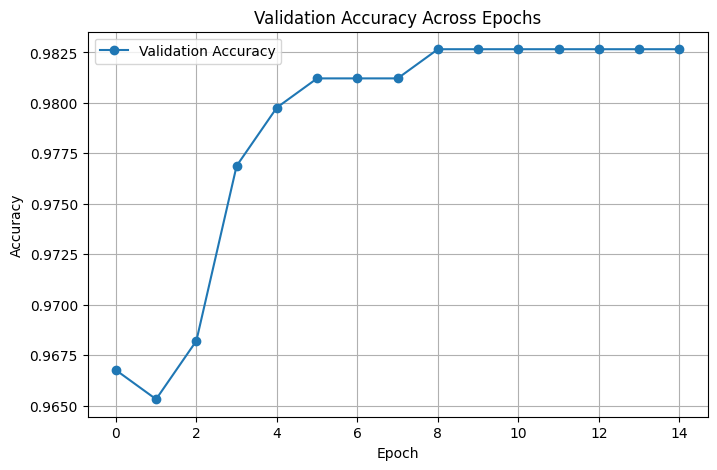

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Validation Accuracy", marker="o")

plt.title("Validation Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
trainer.evaluate(test_dataset)

{'eval_loss': 1.4467087984085083,
 'eval_accuracy': 0.7471264367816092,
 'eval_runtime': 2.6143,
 'eval_samples_per_second': 33.279,
 'eval_steps_per_second': 2.295,
 'epoch': 15.0}

In [ ]:
from sklearn.metrics import classification_report

predictions = trainer.predict(test_dataset)
y_pred = predictions.predictions.argmax(axis=1)

print(classification_report(test_labels, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.70      0.74        44
           1       0.72      0.79      0.76        43

    accuracy                           0.75        87
   macro avg       0.75      0.75      0.75        87
weighted avg       0.75      0.75      0.75        87

